# PhishGuard - Modelo de IA para Detección de Phishing Bancario

Este notebook entrena un modelo de Machine Learning que analiza URLs y las clasifica como **legítimas** o **phishing**.

**Orden del notebook:**
1. Instalar librerías
2. Descargar datasets (URLs de phishing y legítimas)
3. Feature engineering (extraer características de cada URL)
4. Entrenar y comparar modelos
5. Evaluar con métricas serias (no solo accuracy)
6. Explicabilidad (por qué el modelo decide lo que decide)
7. Guardar el modelo para usarlo después en la API

## 1. Instalar librerías necesarias

In [ ]:
!pip install python-whois tldextract python-Levenshtein shap xgboost -q

import pandas as pd
import numpy as np
import re
import math
import tldextract
import whois
import Levenshtein
from urllib.parse import urlparse
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.0/117.0 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.5/107.5 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.4/157.4 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 17.2 MB/s eta 0:00:00


## 2. Descargar y cargar los datasets

Combinamos dos fuentes:
- **URLs de phishing**: dataset de PhishTank/OpenPhish (ya volcado a CSV para que no dependan de la API en vivo, que a veces falla)
- **URLs legítimas**: top sitios de Tranco/Alexa (para tener ejemplos de URLs 'normales')

Si el link de descarga automática falla algún día (estas cosas cambian), busquen 'phishing url dataset kaggle' y suban el CSV manualmente a Colab con el botón de la carpeta de la izquierda.

In [ ]:
# DATASET: al ejecutar esta celda aparece un botón 'Elegir archivos'.
# Elegí el CSV que bajaste de Kaggle ('Phishing Site URLs'). Si viene en .zip, también sirve.
# No hace falta saber ni cambiar el nombre del archivo: se detecta solo.

from google.colab import files
import zipfile, glob, os

subido = files.upload()

# Si subieron un .zip, lo descomprimimos
for nombre in list(subido.keys()):
    if nombre.lower().endswith('.zip'):
        with zipfile.ZipFile(nombre) as z:
            z.extractall('.')

csvs = glob.glob('*.csv')
assert csvs, 'No se encontró ningún CSV. Volvé a ejecutar la celda y elegí el archivo.'
NOMBRE_ARCHIVO = csvs[0]
print('Usando archivo:', NOMBRE_ARCHIVO)

df = pd.read_csv(NOMBRE_ARCHIVO)
print('Columnas encontradas:', df.columns.tolist())

# Detectar columnas de URL y etiqueta sin importar mayúsculas/minúsculas
mapa = {c.lower(): c for c in df.columns}
col_url = mapa.get('url')
col_label = mapa.get('label')
assert col_url and col_label, 'El CSV debe tener columnas URL y Label. Revisá las columnas impresas arriba.'

df = df.rename(columns={col_url: 'url', col_label: 'label_texto'})
df['phishing'] = (df['label_texto'].astype(str).str.lower() == 'bad').astype(int)

# Muestra balanceada de hasta 50.000 por clase (el dataset completo tiene más de 500k
# filas y calcular features sobre todo tardaría demasiado en Colab)
n = min(50000, df['phishing'].value_counts().min())
df = pd.concat([
    df[df['phishing'] == 0].sample(n, random_state=42),
    df[df['phishing'] == 1].sample(n, random_state=42),
]).sample(frac=1, random_state=42).reset_index(drop=True)

print(df.shape)
print(df['phishing'].value_counts())
df.head()

Saving archive.zip to archive.zip
Usando archivo: phishing_site_urls.csv
Columnas encontradas: ['URL', 'Label']
(100000, 3)
phishing
1    50000
0    50000
Name: count, dtype: int64


,url,label_texto,phishing
0,tempremiosouro.no-ip.org/,bad,1
1,mxp1100.com,bad,1
2,marbridgeconsulting.com/marbridgedaily/archive...,good,0
3,vivi.site90.net/copa2014/portal.html,bad,1
4,ronaldodrumond.com.br/images/cielo/,bad,1


## 3. Feature Engineering

Acá está el corazón técnico: convertir cada URL en un conjunto de números (features) que el modelo pueda entender.

Cada función de abajo extrae UNA señal de riesgo, con su justificación:

In [ ]:
# Lista de marcas bancarias a proteger (ajustar según el país / bancos que quieran cubrir)
MARCAS_BANCARIAS = [
    'bancoseguro', 'santander', 'itau', 'bbva', 'visa', 'mastercard',
    'banco', 'ueno', 'continental', 'gnb', 'familiar', 'regional'
]

def calcular_entropia(cadena):
    """Mide qué tan 'aleatoria' es una cadena. Dominios generados automáticamente
    por bots de phishing suelen tener alta entropía (ej: xk29fj-bank.com)"""
    if not cadena:
        return 0
    prob = [cadena.count(c) / len(cadena) for c in set(cadena)]
    return -sum(p * math.log2(p) for p in prob)

def distancia_a_marca_conocida(dominio):
    """Calcula la distancia de edición (Levenshtein) al nombre de banco más parecido.
    Una distancia de 1-2 con un dominio distinto = fuerte señal de typosquatting."""
    distancias = [Levenshtein.distance(dominio, marca) for marca in MARCAS_BANCARIAS]
    return min(distancias)

def tiene_ip_en_url(url):
    """Si la URL usa una IP en vez de un dominio (ej: http://192.168.1.1/banco),
    es una señal de alto riesgo casi siempre."""
    patron_ip = r'(\d{1,3}\.){3}\d{1,3}'
    return 1 if re.search(patron_ip, url) else 0

def contar_subdominios(dominio_completo):
    """Muchos subdominios (ej: login.seguro.banco.paginafalsa.com) es técnica
    común para confundir visualmente al usuario."""
    return dominio_completo.count('.')

def extraer_features(url):
    """Función principal: toma una URL cruda y devuelve un diccionario
    con todas las features numéricas para el modelo."""
    try:
        parsed = urlparse(url if url.startswith('http') else 'http://' + url)
        ext = tldextract.extract(url)
        dominio = ext.domain
        dominio_completo = f"{ext.subdomain}.{ext.domain}.{ext.suffix}" if ext.subdomain else f"{ext.domain}.{ext.suffix}"

        features = {
            'longitud_url': len(url),
            'longitud_dominio': len(dominio),
            'cantidad_puntos': dominio_completo.count('.'),
            'cantidad_guiones': dominio.count('-'),
            'cantidad_arrobas': url.count('@'),
            'cantidad_digitos': sum(c.isdigit() for c in dominio),
            'tiene_https': 1 if parsed.scheme == 'https' else 0,
            'tiene_ip': tiene_ip_en_url(url),
            'cantidad_subdominios': contar_subdominios(dominio_completo),
            'entropia_dominio': calcular_entropia(dominio),
            'distancia_marca_bancaria': distancia_a_marca_conocida(dominio),
            'longitud_path': len(parsed.path),
            'tiene_palabra_sospechosa': 1 if any(p in url.lower() for p in ['login', 'verify', 'secure', 'account', 'update', 'confirm']) else 0,
        }
        return features
    except Exception:
        return None

# Prueba rápida de la función con un ejemplo
extraer_features('http://bancosegur0-login.verificar-cuenta.com/update')

{'longitud_url': 52,
 'longitud_dominio': 16,
 'cantidad_puntos': 2,
 'cantidad_guiones': 1,
 'cantidad_arrobas': 0,
 'cantidad_digitos': 0,
 'tiene_https': 0,
 'tiene_ip': 0,
 'cantidad_subdominios': 2,
 'entropia_dominio': 3.375,
 'distancia_marca_bancaria': 12,
 'longitud_path': 7,
 'tiene_palabra_sospechosa': 1}

### Nota sobre WHOIS (antigüedad del dominio)

La consulta WHOIS es lenta (una petición de red por URL) y algunos dominios no la responden. Por eso NO la metemos en el bucle masivo de entrenamiento (tardaría horas con miles de URLs).

La usamos más adelante, en la API real, donde el usuario analiza UNA URL a la vez y sí importa esperar 1-2 segundos por esa información extra.

In [ ]:
def antiguedad_dominio_dias(dominio_completo):
    """Consulta WHOIS y devuelve hace cuántos días se registró el dominio.
    Se usa en la API en tiempo real, no en el entrenamiento masivo."""
    try:
        info = whois.whois(dominio_completo)
        fecha_creacion = info.creation_date
        if isinstance(fecha_creacion, list):
            fecha_creacion = fecha_creacion[0]
        if fecha_creacion:
            return (datetime.now() - fecha_creacion).days
        return -1  # no se pudo determinar
    except Exception:
        return -1

# Ejemplo (esto sí hace una consulta real a internet)
antiguedad_dominio_dias('google.com')

-1

## 4. Aplicar el feature engineering a todo el dataset

In [ ]:
COLUMNA_URL = 'url'
COLUMNA_LABEL = 'phishing'

# --- CORRECCIÓN DE UN SESGO DEL DATASET ---
# En este tipo de datasets, las URLs legítimas casi siempre traen una ruta larga
# (www.sitio.com/pagina/...) y los dominios "pelados" (www.google.com) aparecen casi solo
# como phishing. El modelo aprende ese atajo ("sin ruta = phishing") y termina marcando
# google.com como phishing. Para evitarlo agregamos copias "solo dominio" de la mitad de las
# URLs, con su misma etiqueta: así tener o no ruta deja de servir para separar las clases.
from urllib.parse import urlparse

def solo_dominio(u):
    u = str(u)
    # Eliminamos corchetes para evitar errores de IPv6 inválido en urlparse
    u = u.replace('[', '').replace(']', '')
    p = urlparse(u if '://' in u else 'http://' + u)
    return p.netloc

df['grupo'] = df.index  # cada URL y su copia comparten grupo (se usa para no filtrar datos al evaluar)
copias = df.sample(frac=0.5, random_state=42).copy()
copias[COLUMNA_URL] = copias[COLUMNA_URL].map(solo_dominio)
copias = copias[copias[COLUMNA_URL] != '']
df_ampliado = pd.concat([df, copias]).reset_index(drop=True)
print(f"URLs originales: {len(df)} | con copias solo-dominio: {len(df_ampliado)}")

# Este paso tarda unos minutos
features_list = []
indices_validos = []
for i, url in enumerate(df_ampliado[COLUMNA_URL]):
    f = extraer_features(str(url))
    if f:
        features_list.append(f)
        indices_validos.append(i)

df_features = pd.DataFrame(features_list)
df_features['label'] = df_ampliado[COLUMNA_LABEL].values[indices_validos]
df_features['grupo'] = df_ampliado['grupo'].values[indices_validos]

# Las URLs de este dataset casi nunca traen 'http://' o 'https://', así que 'tiene_https'
# no aporta información real (sería casi siempre 0). La sacamos para no ensuciar el modelo.
# La API igual la calcula, pero se filtra sola porque usa el orden de columnas_features.pkl.
df_features = df_features.drop(columns=['tiene_https'])
df_features = df_features.dropna()

print(f"Dataset final: {df_features.shape[0]} URLs, {df_features.shape[1]-2} features")
print([c for c in df_features.columns if c not in ('label', 'grupo')])
df_features.head()

URLs originales: 100000 | con copias solo-dominio: 149831
Dataset final: 149830 URLs, 12 features
['longitud_url', 'longitud_dominio', 'cantidad_puntos', 'cantidad_guiones', 'cantidad_arrobas', 'cantidad_digitos', 'tiene_ip', 'cantidad_subdominios', 'entropia_dominio', 'distancia_marca_bancaria', 'longitud_path', 'tiene_palabra_sospechosa']


,longitud_url,longitud_dominio,cantidad_puntos,cantidad_guiones,cantidad_arrobas,cantidad_digitos,tiene_ip,cantidad_subdominios,entropia_dominio,distancia_marca_bancaria,longitud_path,tiene_palabra_sospechosa,label,grupo
0,25,5,2,1,0,0,0,2,2.321928,5,1,0,1,0
1,11,7,1,0,0,4,0,1,2.235926,7,0,0,1,1
2,113,19,1,0,0,0,0,1,3.826875,14,90,0,0,2
3,36,6,2,0,0,2,0,2,2.584963,4,21,0,1,3
4,35,14,2,0,0,0,0,2,2.842371,11,14,0,1,4


## 5. Entrenar y comparar varios modelos

No usamos un solo algoritmo a ciegas: comparamos 3 y justificamos cuál conviene.

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold

grupos = df_features['grupo']
X = df_features.drop(['label', 'grupo'], axis=1)
y = df_features['label']

# Separamos train/test POR GRUPO: una URL y su copia "solo dominio" siempre quedan del mismo
# lado. Si no, el modelo vería en entrenamiento casi la misma URL que luego se evalúa en test
# y las métricas saldrían infladas.
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_train, idx_test = next(gss.split(X, y, groups=grupos))
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train = grupos.iloc[idx_train]

modelos = {
    'Regresión Logística': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42)
}

resultados = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]

    cv_scores = cross_val_score(modelo, X_train, y_train, cv=GroupKFold(n_splits=5), groups=g_train, scoring='f1')

    resultados[nombre] = {
        'modelo': modelo,
        'auc': roc_auc_score(y_test, y_prob),
        'f1_cv_mean': cv_scores.mean(),
        'f1_cv_std': cv_scores.std(),
        'reporte': classification_report(y_test, y_pred, output_dict=True)
    }

    print(f"\n===== {nombre} =====")
    print(f"AUC-ROC: {resultados[nombre]['auc']:.4f}")
    print(f"F1 (validación cruzada, 5-fold): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(classification_report(y_test, y_pred, target_names=['Legítimo', 'Phishing']))


===== Regresión Logística =====
AUC-ROC: 0.7061
F1 (validación cruzada, 5-fold): 0.5879 ± 0.0021
              precision    recall  f1-score   support

    Legítimo       0.61      0.81      0.70     19844
    Phishing       0.72      0.49      0.58     20078

    accuracy                           0.65     39922
   macro avg       0.67      0.65      0.64     39922
weighted avg       0.67      0.65      0.64     39922


===== Random Forest =====
AUC-ROC: 0.8732
F1 (validación cruzada, 5-fold): 0.7905 ± 0.0007
              precision    recall  f1-score   support

    Legítimo       0.77      0.81      0.79     19844
    Phishing       0.80      0.76      0.78     20078

    accuracy                           0.79     39922
   macro avg       0.79      0.79      0.79     39922
weighted avg       0.79      0.79      0.79     39922


===== XGBoost =====
AUC-ROC: 0.8490
F1 (validación cruzada, 5-fold): 0.7567 ± 0.0026
              precision    recall  f1-score   support

    Legítimo   

### ¿Por qué importa mirar más que el accuracy?

En este problema, dejar pasar un phishing real (falso negativo) es mucho peor que marcar por error un sitio legítimo como sospechoso (falso positivo). Por eso miramos especialmente **recall de la clase Phishing** (qué % de los phishing reales detectamos) más que el accuracy general.

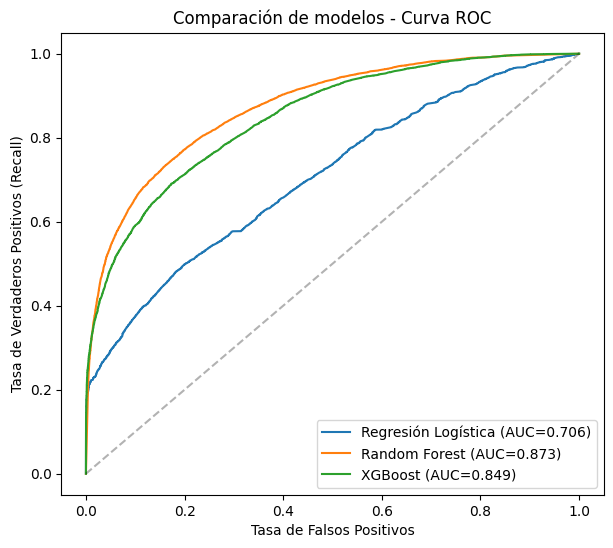

In [ ]:
# Curva ROC comparativa de los 3 modelos
plt.figure(figsize=(7,6))
for nombre, res in resultados.items():
    y_prob = res['modelo'].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC={res['auc']:.3f})")

plt.plot([0,1],[0,1],'k--', alpha=0.3)
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.title('Comparación de modelos - Curva ROC')
plt.legend()
plt.show()

## 5.1 Ajustar el umbral de decisión

Por defecto, el modelo clasifica como 'Phishing' cuando la probabilidad supera 0.5. Pero en este problema, dejar pasar un phishing real (falso negativo) es más costoso que marcar por error un sitio legítimo (falso positivo).

Bajando el umbral, el modelo se vuelve más 'desconfiado': detecta más phishing real, a costa de generar algunos falsos positivos de más. Probamos varios umbrales para elegir el punto que mejor balancea esto.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Usamos XGBoost (el elegido para producción)
modelo_final = resultados['XGBoost']['modelo']
y_prob_final = modelo_final.predict_proba(X_test)[:, 1]

umbrales = [0.5, 0.45, 0.40, 0.35, 0.30, 0.25]
filas = []
for u in umbrales:
    y_pred_u = (y_prob_final >= u).astype(int)
    filas.append({
        'umbral': u,
        'recall_phishing': recall_score(y_test, y_pred_u),
        'precision_phishing': precision_score(y_test, y_pred_u),
        'f1_phishing': f1_score(y_test, y_pred_u),
        'falsos_negativos': ((y_test == 1) & (y_pred_u == 0)).sum(),
        'falsos_positivos': ((y_test == 0) & (y_pred_u == 1)).sum(),
    })

tabla_umbrales = pd.DataFrame(filas)
tabla_umbrales

,umbral,recall_phishing,precision_phishing,f1_phishing,falsos_negativos,falsos_positivos
0,0.50,0.701215,0.791845,0.743779,5999,3701
1,0.45,0.775525,0.741512,0.758137,4507,5428
2,0.40,0.846897,0.698747,0.765722,3074,7331
3,0.35,0.888834,0.676677,0.768380,2232,8527
4,0.30,0.923000,0.650862,0.763403,1546,9941
5,0.25,0.949099,0.619546,0.749705,1022,11702


**Cómo leer esta tabla:**
- `falsos_negativos`: cantidad de phishing REAL que el modelo dejó pasar (el error caro).
- `falsos_positivos`: cantidad de sitios legítimos marcados por error como riesgo (molesto, pero menos grave).

Elijan el umbral donde `falsos_negativos` baja notablemente sin que `falsos_positivos` se dispare demasiado. Un punto de partida razonable suele estar entre 0.30 y 0.40. Anoten el umbral elegido — lo van a necesitar como constante en la API.

In [ ]:
# Guardamos el umbral elegido junto con el modelo, para que la API lo use directamente
UMBRAL_ELEGIDO = 0.35  # <-- ajustar según la tabla de arriba

import joblib
joblib.dump(UMBRAL_ELEGIDO, 'umbral_decision.pkl')
print(f"Umbral guardado: {UMBRAL_ELEGIDO}")

Umbral guardado: 0.35


## 6. Explicabilidad: ¿por qué el modelo decide lo que decide?

Esto es clave para el contexto bancario: no alcanza con clasificar, hay que poder explicar la decisión (importante por temas regulatorios/de confianza).

In [ ]:
import shap

mejor_modelo_nombre = max(resultados, key=lambda k: resultados[k]['auc'])
mejor_modelo = resultados[mejor_modelo_nombre]['modelo']
print(f"Mejor modelo según AUC: {mejor_modelo_nombre}")

# Usamos una MUESTRA de X_test (no todo el dataset) para que SHAP sea rápido.
# 300-500 filas alcanzan de sobra para ver qué features pesan más.
X_sample = X_test.sample(min(300, len(X_test)), random_state=42)

explainer = shap.TreeExplainer(mejor_modelo)
shap_values = explainer.shap_values(X_sample, check_additivity=False)

shap.summary_plot(shap_values, X_sample, plot_type='bar')

Mejor modelo según AUC: Random Forest


Este gráfico muestra qué features pesan más en la decisión del modelo en general. Para explicar UNA predicción puntual (ej. 'por qué este link específico fue marcado como riesgo alto'), se usa `shap.force_plot()` sobre esa fila — lo van a necesitar para mostrar el 'por qué' en la interfaz de usuario.

## 7. Guardar el modelo entrenado para usarlo en la API

In [ ]:
import joblib

# Usamos XGBoost de forma consistente con el umbral ajustado arriba
modelo_para_produccion = resultados['XGBoost']['modelo']

joblib.dump(modelo_para_produccion, 'modelo_phishing.pkl')
joblib.dump(list(X.columns), 'columnas_features.pkl')
# umbral_decision.pkl ya se guardó en el paso anterior

print("Modelo guardado. Descargalo desde el panel de archivos de Colab (ícono de carpeta a la izquierda)")
print("Estos 3 archivos (.pkl) son los que va a cargar el backend/API para hacer predicciones sin reentrenar cada vez.")